# HW2 --- Data-Based (Surrogate) Modeling

Fill in the `# TODO` sections below to answer each question in `HW2.pdf`.
Dataset: [`aero_naca4_airfoil_panel.csv`](https://github.com/Ahmed-Bayoumy/MECH559/blob/DEV/Datasets/aero_naca4_airfoil_panel.csv)
(NACA 4-digit airfoil, vortex-panel method, $p=500$).

- **Inputs (6):** `max_camber_m`, `camber_pos_p`, `thickness_t`, `alpha_deg`, `mach`, `reynolds`
  (use $\log_{10}$(reynolds) in place of the raw column).
- **Output:** `CL`.
- **"Scaled inputs"** = per-column min--max scaling to $[0,1]$ using **training-set** bounds.

Starter code from Lecture 4's notebooks is linked in `HW2.pdf`; adapt it rather than
writing every model from a blank page. Each question below is copied verbatim from `HW2.pdf`;
Rename this file `<McGill_ID>_HW2.ipynb` before submitting.

## Setup: imports and data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.gaussian_process.kernels import RBF as RBFKernel, ConstantKernel
from sklearn.model_selection import KFold
from scipy.interpolate import RBFInterpolator
from scipy.spatial.distance import cdist
import warnings

RNG = 559
plt.rcParams.update({'font.size': 11, 'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})
COLORS = {'fit': '#00798C', 'alt': '#D1495B', 'best': '#EDAE49'}

# Works when run from the notebook directory or from the course workspace root.
csv_path = next((p for p in (Path('aero_naca4_airfoil_panel.csv'),
                            Path('MECH559_repo/02_assignmnet/aero_naca4_airfoil_panel.csv'))
                 if p.exists()), None)
if csv_path is None:
    raise FileNotFoundError('Place aero_naca4_airfoil_panel.csv beside this notebook.')
df = pd.read_csv(csv_path)
train = df.loc[df['split'] == 'train'].reset_index(drop=True)
test = df.loc[df['split'] == 'test'].reset_index(drop=True)
print(f'total={len(df)} train={len(train)} test={len(test)}')

raw_cols = ['max_camber_m', 'camber_pos_p', 'thickness_t', 'alpha_deg', 'mach']
feat_names = raw_cols + ['log10_reynolds']
def make_raw(d):
    return np.column_stack([d[raw_cols].to_numpy(dtype=float),
                            np.log10(d['reynolds'].to_numpy(dtype=float))])
Xtr, ytr = make_raw(train), train['CL'].to_numpy(dtype=float)
Xte, yte = make_raw(test), test['CL'].to_numpy(dtype=float)
def rmse(y, yhat):
    return float(np.sqrt(np.mean((y - yhat) ** 2)))
def r2(y, yhat):
    return float(1 - np.sum((y - yhat) ** 2) / np.sum((y - np.mean(y)) ** 2))
def scale_from(Xfit, Xquery):
    lo, hi = Xfit.min(axis=0), Xfit.max(axis=0)
    assert np.all(hi > lo)
    return (Xfit - lo) / (hi - lo), (Xquery - lo) / (hi - lo)
Xtr_s, Xte_s = scale_from(Xtr, Xte)
kf = KFold(n_splits=5, shuffle=True, random_state=RNG)
folds = list(kf.split(Xtr))
print('Xtr shape:', Xtr.shape, 'Xte shape:', Xte.shape)

total=500 train=407 test=93
Xtr shape: (407, 6) Xte shape: (93, 6)


## Question 1 --- Design of experiments

[`aero_naca4_airfoil_panel.csv`](https://github.com/Ahmed-Bayoumy/MECH559/blob/DEV/Datasets/aero_naca4_airfoil_panel.csv) was sampled with LHS ($n=6$, $p=500$), not a full-factorial grid. An LHS with $p$ points has $p$ distinct levels in every 1-D projection. Compute the full-factorial grid size needed to match this 1-D resolution ($p^{n}$ runs) and compare it to $p$; conversely, find how many levels per dimension a grid of at most $p$ runs can afford ($\lfloor p^{1/n}\rfloor$). Briefly explain why LHS avoids this *curse of dimensionality* while still space-filling well in 1-D.

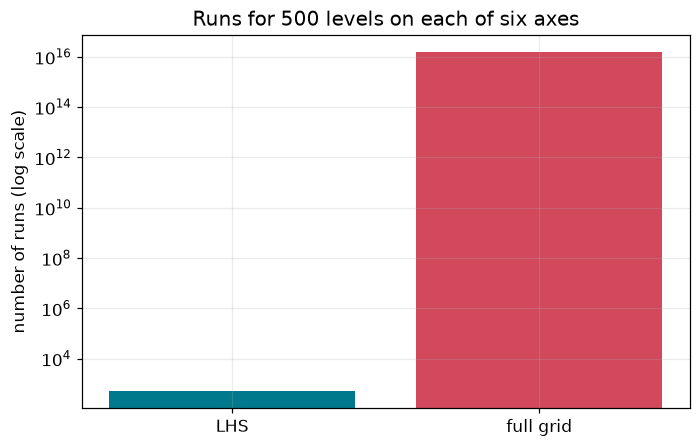

Matching 500 levels on all 6 axes requires 15,625,000,000,000,000 factorial runs, 31,250,000,000,000 times the LHS budget of 500.
With at most 500 runs, a full grid affords 2 levels/axis (64 runs); 3 levels need 729.
LHS places one point in each of 500 intervals on every input axis, while permuting interval pairings across axes. Its strong guarantee is marginal (1-D) coverage; joint-space gaps may still occur.


In [2]:
n, p = 6, 500
grid_full = p ** n
levels_afford = int(np.floor(p ** (1 / n)))
assert levels_afford ** n <= p < (levels_afford + 1) ** n
print(f'Matching {p} levels on all {n} axes requires {grid_full:,} factorial runs, '
      f'{grid_full / p:,.0f} times the LHS budget of {p}.')
print(f'With at most {p} runs, a full grid affords {levels_afford} levels/axis '
      f'({levels_afford ** n} runs); {levels_afford + 1} levels need {(levels_afford + 1) ** n}.')
print('LHS places one point in each of 500 intervals on every input axis, while '
      'permuting interval pairings across axes. Its strong guarantee is marginal '
      '(1-D) coverage; joint-space gaps may still occur.')
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.bar(['LHS', 'full grid'], [p, grid_full], color=[COLORS['fit'], COLORS['alt']])
ax.set_yscale('log')
ax.set(ylabel='number of runs (log scale)', title='Runs for 500 levels on each of six axes')
plt.tight_layout(); plt.show()

**Answer and interpretation.** LHS stratifies each marginal axis, then independently permutes strata across dimensions. A full grid must enumerate every level combination. The LHS guarantee concerns one-dimensional projections; it does not guarantee uniform joint spacing.

## Question 2 --- Polynomial regression from first principles

Using the `train` rows, fit an affine model $\hat{y}(\mathbf{x};\mathbf{w}) = w_0 + \sum_{j=1}^{6} w_j x_j$ for `CL` (inputs: `max_camber_m`, `camber_pos_p`, `thickness_t`, `alpha_deg`, `mach`, $\log_{10}$(`reynolds`)) by solving the normal equations $\mathbf{Z}^{\mathsf T}\mathbf{Z}\,\mathbf{w} = \mathbf{Z}^{\mathsf T}\mathbf{y}$ directly -- adapt the Starter Code notebook's `normal_equations_fit`, or assemble $\mathbf{Z}$ yourself and pass $\mathbf{Z}^{\mathsf T}\mathbf{Z}$ and $\mathbf{Z}^{\mathsf T}\mathbf{y}$ to `numpy.linalg.solve` or MATLAB's backslash operator (no canned regression function; note that `lstsq`, or backslash applied to $\mathbf{Z}$ and $\mathbf{y}$ directly, does *not* form $\mathbf{Z}^{\mathsf T}\mathbf{Z}$). Report $\mathbf{w}$ and the test RMSE/$R^2$, then confirm both match `scikit-learn`'s `LinearRegression` (or MATLAB's `fitlm`).

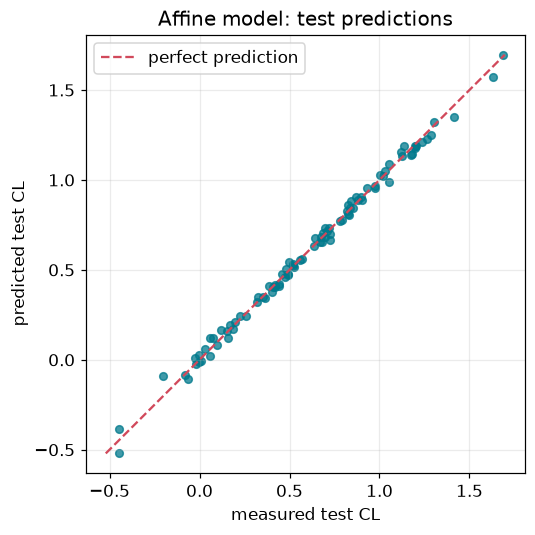

          term  normal equations  LinearRegression
     intercept         -0.293009         -0.293009
  max_camber_m         13.848945         13.848945
  camber_pos_p          0.346723          0.346723
   thickness_t          0.599522          0.599522
     alpha_deg          0.125721          0.125721
          mach          0.176949          0.176949
log10_reynolds          0.004182          0.004182
Normal equations: test RMSE=0.030767, R2=0.995256
LinearRegression: test RMSE=0.030767, R2=0.995256
Max coefficient difference: 8.527e-14; max test prediction difference: 7.994e-15


In [3]:
Ztr = np.column_stack([np.ones(len(Xtr)), Xtr])
Zte = np.column_stack([np.ones(len(Xte)), Xte])
w_affine = np.linalg.solve(Ztr.T @ Ztr, Ztr.T @ ytr)
yhat_affine = Zte @ w_affine
lr = LinearRegression().fit(Xtr, ytr)
w_sklearn = np.r_[lr.intercept_, lr.coef_]
yhat_sklearn = lr.predict(Xte)
coef_table = pd.DataFrame({'term': ['intercept'] + feat_names,
                           'normal equations': w_affine,
                           'LinearRegression': w_sklearn})
display(coef_table)
print(f'Normal equations: test RMSE={rmse(yte, yhat_affine):.6f}, R2={r2(yte, yhat_affine):.6f}')
print(f'LinearRegression: test RMSE={rmse(yte, yhat_sklearn):.6f}, R2={r2(yte, yhat_sklearn):.6f}')
print(f'Max coefficient difference: {np.max(np.abs(w_affine - w_sklearn)):.3e}; '
      f'max test prediction difference: {np.max(np.abs(yhat_affine - yhat_sklearn)):.3e}')
assert np.allclose(w_affine, w_sklearn, rtol=1e-5, atol=1e-5)
assert np.allclose(yhat_affine, yhat_sklearn, rtol=1e-5, atol=1e-5)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(yte, yhat_affine, s=25, color=COLORS['fit'], alpha=0.75)
lims = [min(yte.min(), yhat_affine.min()), max(yte.max(), yhat_affine.max())]
ax.plot(lims, lims, '--', color=COLORS['alt'], label='perfect prediction')
ax.set(xlabel='measured test CL', ylabel='predicted test CL', title='Affine model: test predictions')
ax.legend(); plt.tight_layout(); plt.show()

**Answer and interpretation.** The manual fit solves the requested normal equations on the six unscaled inputs, with Reynolds number replaced by its base-10 logarithm. The library comparison checks both coefficients and held-out predictions.

## Question 3 --- Ill-conditioning and ridge regularization

Extend question 2 to a pure quadratic (add $w_{j+6}\,x_j^2$, 13 columns in $\mathbf{Z}$) and report $\kappa(\mathbf{Z}^{\mathsf T}\mathbf{Z})$. Min-max scale the inputs to $[0,1]$ (training-set bounds), rebuild $\mathbf{Z}$, and report the new condition number. Sweep the ridge penalty $\lambda \in \{0, 10^{-4}, 10^{-2}, 1, 100\}$ (adapt `ridge_fit`, i.e. $\mathbf{w}_{\text{ridge}} = (\mathbf{Z}^{\mathsf T}\mathbf{Z}+\lambda\mathbf{I})^{-1}\mathbf{Z}^{\mathsf T}\mathbf{y}$ on the scaled $\mathbf{Z}$; this penalizes $w_0$ too, so if you use `sklearn.linear_model.Ridge` pass your own column of ones with `fit_intercept=False` to get the same result); using 5-fold CV on the training set, plot CV RMSE vs. $\lambda$, report the best $\lambda$, and compare its test RMSE/$R^2$ to $\lambda=0$. **Relate this to the bias--variance trade-off and to $\kappa(\mathbf{Z}^{\mathsf T}\mathbf{Z}+\lambda\mathbf{I})$.**

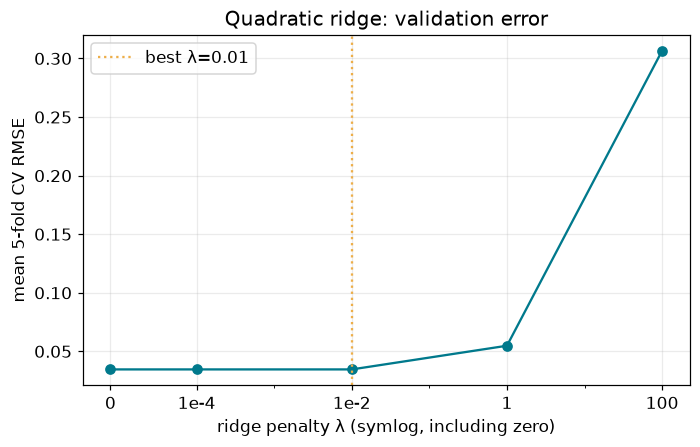

Quadratic design has 13 columns.
cond(Z.T @ Z), raw=2.604e+10, scaled=1.496e+03
  lambda  mean CV RMSE  cond(Z.T @ Z + lambda I)
  0.0000      0.034557               1496.418795
  0.0001      0.034556               1496.247300
  0.0100      0.034553               1479.461864
  1.0000      0.054765                697.538036
100.0000      0.306566                 13.925744
Selected lambda=0.01; intercept is included in ridge penalty.
lambda=0: test RMSE=0.030816, R2=0.995241
lambda=0.01: test RMSE=0.030776, R2=0.995254
Ridge raises the small eigenvalues and reduces coefficient sensitivity, at the cost of bias. Excessive penalty shrinks all coefficients, including the intercept.


In [4]:
def quad_design(X):
    return np.column_stack([np.ones(len(X)), X, X ** 2])

Ztr_quad_raw = quad_design(Xtr)
Ztr_quad_s, Zte_quad_s = quad_design(Xtr_s), quad_design(Xte_s)
kappa_raw = np.linalg.cond(Ztr_quad_raw.T @ Ztr_quad_raw)
kappa_scaled = np.linalg.cond(Ztr_quad_s.T @ Ztr_quad_s)
print(f'Quadratic design has {Ztr_quad_s.shape[1]} columns.')
print(f'cond(Z.T @ Z), raw={kappa_raw:.3e}, scaled={kappa_scaled:.3e}')

lambdas = np.array([0, 1e-4, 1e-2, 1, 100.])
ridge_cv = []
for lam in lambdas:
    errors = []
    for tr_idx, va_idx in folds:
        Xf, Xv = scale_from(Xtr[tr_idx], Xtr[va_idx])
        Zf, Zv = quad_design(Xf), quad_design(Xv)
        w = np.linalg.solve(Zf.T @ Zf + lam * np.eye(Zf.shape[1]), Zf.T @ ytr[tr_idx])
        errors.append(rmse(ytr[va_idx], Zv @ w))
    ridge_cv.append(np.mean(errors))
ridge_cv = np.array(ridge_cv)
best_ridge_lam = float(lambdas[np.argmin(ridge_cv)])
ridge_table = pd.DataFrame({'lambda': lambdas, 'mean CV RMSE': ridge_cv,
                             'cond(Z.T @ Z + lambda I)':
                             [np.linalg.cond(Ztr_quad_s.T @ Ztr_quad_s + lam * np.eye(13))
                              for lam in lambdas]})
display(ridge_table)
print(f'Selected lambda={best_ridge_lam:g}; intercept is included in ridge penalty.')
def ridge_predict(lam):
    w = np.linalg.solve(Ztr_quad_s.T @ Ztr_quad_s + lam * np.eye(13), Ztr_quad_s.T @ ytr)
    return Zte_quad_s @ w
yhat_ridge_zero = ridge_predict(0)
yhat_ridge = ridge_predict(best_ridge_lam)
print(f'lambda=0: test RMSE={rmse(yte, yhat_ridge_zero):.6f}, R2={r2(yte, yhat_ridge_zero):.6f}')
print(f'lambda={best_ridge_lam:g}: test RMSE={rmse(yte, yhat_ridge):.6f}, R2={r2(yte, yhat_ridge):.6f}')
fig, ax = plt.subplots(figsize=(6.5, 4.2))
# symlog makes the unpenalized zero visible beside log-spaced positive penalties.
ax.plot(lambdas, ridge_cv, 'o-', color=COLORS['fit'])
ax.set_xscale('symlog', linthresh=1e-4)
ax.axvline(best_ridge_lam, color=COLORS['best'], ls=':', label=f'best λ={best_ridge_lam:g}')
ax.set(xlabel='ridge penalty λ (symlog, including zero)', ylabel='mean 5-fold CV RMSE',
       title='Quadratic ridge: validation error')
ax.set_xticks(lambdas, ['0', '1e-4', '1e-2', '1', '100'])
ax.legend(); plt.tight_layout(); plt.show()
print('Ridge raises the small eigenvalues and reduces coefficient sensitivity, at the '
      'cost of bias. Excessive penalty shrinks all coefficients, including the intercept.')

**Answer and interpretation.** Pure quadratic means an intercept, six linear terms, and six squares, with no cross-products. Scaling is fitted independently inside each CV training fold. The ridge penalty includes the intercept. Increasing λ improves matrix conditioning and lowers estimation variance, while excessive shrinkage adds bias.

## Question 4 --- RBF and its spread parameter

Fit a Gaussian RBF surrogate $\phi(r)=\exp(-\lambda r^2)$ for `CL` (same 6 scaled inputs) with the Starter Code notebook (replace its 1-D distance by the Euclidean distance in 6-D) or a library, sweeping the spread over $\geq4$ values across orders of magnitude (e.g. $\lambda\in[10^{-4},10^{3}]$; large $\lambda$ = narrow basis functions). If you use `scipy.interpolate.RBFInterpolator`, set `kernel='gaussian'` and `epsilon` $=\sqrt{\lambda}$ -- the default thin-plate kernel ignores `epsilon`; MATLAB's `newrbe` spread $s$ corresponds to $\lambda=(0.8326/s)^2$. Using 5-fold CV, plot CV RMSE vs. spread and identify the best value. **Relate the too-narrow/too-wide extremes to the "good spread" vs. "poor spread" behavior from lecture.**

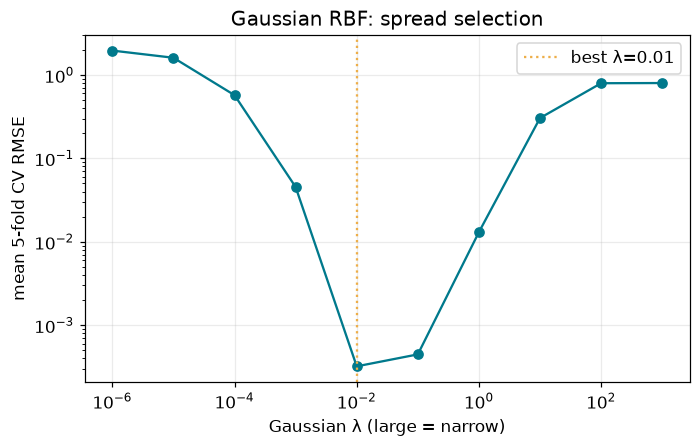

     lambda  mean CV RMSE
   0.000001      1.962631
   0.000010      1.609502
   0.000100      0.573025
   0.001000      0.045375
   0.010000      0.000321
   0.100000      0.000446
   1.000000      0.013047
  10.000000      0.304625
 100.000000      0.796724
1000.000000      0.800736
Selected Gaussian lambda=0.01 (epsilon=0.1).
RBF test RMSE=0.000273, R2=1.000000
Broad-end CV RMSE=1.963; selected-spread CV RMSE=0.0003206; narrow-end CV RMSE=0.8007.
At lambda <= 1e-3 the Gaussian bases are too broad: their columns become nearly dependent, producing an ill-conditioned interpolation system and worse validation error. Lambda=0.01 retains broad, useful overlap without entering that unstable regime; the narrow end has too little influence between training centers.


In [5]:
# The scipy Gaussian kernel is exp(-(epsilon*r)^2); epsilon=sqrt(lambda).
# degree=-1 removes the polynomial tail, matching the lecture's Gaussian interpolant.
spreads = np.array([1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100, 1000.])
rbf_cv = []
for lam in spreads:
    errors = []
    for tr_idx, va_idx in folds:
        Xf, Xv = scale_from(Xtr[tr_idx], Xtr[va_idx])
        try:
            model = RBFInterpolator(Xf, ytr[tr_idx], kernel='gaussian',
                                    epsilon=np.sqrt(lam), degree=-1)
            pred = model(Xv)
            errors.append(rmse(ytr[va_idx], pred))
        except np.linalg.LinAlgError:
            errors.append(np.inf)
    rbf_cv.append(np.mean(errors))
rbf_cv = np.array(rbf_cv)
assert np.isfinite(rbf_cv).any(), 'Every Gaussian interpolation solve failed.'
best_rbf_lam = float(spreads[np.argmin(rbf_cv)])
display(pd.DataFrame({'lambda': spreads, 'mean CV RMSE': rbf_cv}))
print(f'Selected Gaussian lambda={best_rbf_lam:g} (epsilon={np.sqrt(best_rbf_lam):.5g}).')
rbf = RBFInterpolator(Xtr_s, ytr, kernel='gaussian',
                      epsilon=np.sqrt(best_rbf_lam), degree=-1)
yhat_rbf = rbf(Xte_s)
print(f'RBF test RMSE={rmse(yte, yhat_rbf):.6f}, R2={r2(yte, yhat_rbf):.6f}')
fig, ax = plt.subplots(figsize=(6.5, 4.2))
finite = np.isfinite(rbf_cv)
ax.loglog(spreads[finite], rbf_cv[finite], 'o-', color=COLORS['fit'])
ax.axvline(best_rbf_lam, color=COLORS['best'], ls=':', label=f'best λ={best_rbf_lam:g}')
ax.set(xlabel='Gaussian λ (large = narrow)', ylabel='mean 5-fold CV RMSE',
       title='Gaussian RBF: spread selection')
ax.legend(); plt.tight_layout(); plt.show()
print(f'Broad-end CV RMSE={rbf_cv[0]:.4g}; selected-spread CV RMSE='
      f'{rbf_cv[np.argmin(rbf_cv)]:.4g}; narrow-end CV RMSE={rbf_cv[-1]:.4g}.')
print('At lambda <= 1e-3 the Gaussian bases are too broad: their columns become '
      'nearly dependent, producing an ill-conditioned interpolation system and '
      'worse validation error. Lambda=0.01 retains broad, useful overlap without '
      'entering that unstable regime; the narrow end has too little influence '
      'between training centers.')

**Answer and interpretation.** Each Gaussian RBF is centered on a training point. The interpolation weights solve the Gaussian kernel matrix system. The extended sweep shows that $\lambda\leq10^{-3}$ is too broad: the kernel matrix becomes nearly singular and validation error rises. The selected $\lambda=0.01$ retains useful broad overlap, while the larger, narrow values have too little influence between training centers.

## Question 5 --- Neural network width as a complexity knob

Fit a single-hidden-layer network for `CL` (same 6 scaled inputs) with `MLPRegressor` (use `solver='lbfgs'`, `max_iter=5000`, a fixed `random_state`; the default `adam` with 200 iterations does not converge here) or `fitrnet`, sweeping the hidden-layer width over $\geq4$ values (e.g. 2, 8, 32, 64). Using 5-fold CV, plot CV RMSE vs. width and identify where under- and overfitting set in.

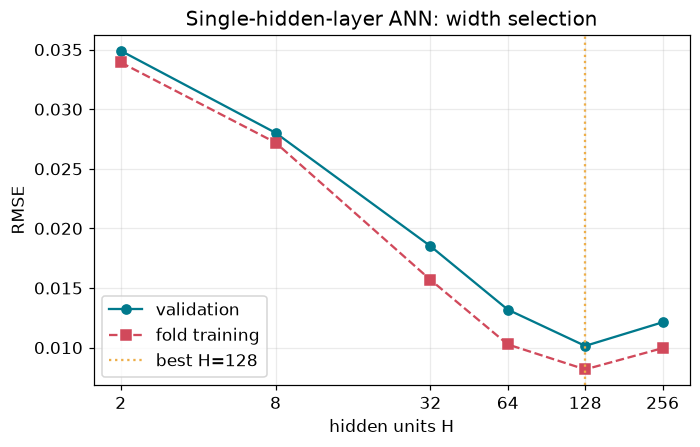

 hidden width  mean CV RMSE  mean fold training RMSE
            2      0.034901                 0.033919
            8      0.028015                 0.027193
           32      0.018514                 0.015688
           64      0.013183                 0.010264
          128      0.010139                 0.008167
          256      0.012121                 0.009952
Selected width=128; activation=ReLU, alpha=1e-4 (sklearn defaults).
ANN test RMSE=0.010782, R2=0.999417
Width 2 has the highest training and validation errors, consistent with underfitting. Validation RMSE decreases through width 128, then increases at width 256 while training error remains low. The widening generalization gap is evidence that overfitting begins beyond the CV-selected width of 128.


In [6]:
widths = np.array([2, 8, 32, 64, 128, 256])
ann_cv, ann_train = [], []
for width in widths:
    val_errors, train_errors = [], []
    for tr_idx, va_idx in folds:
        Xf, Xv = scale_from(Xtr[tr_idx], Xtr[va_idx])
        mlp_fold = MLPRegressor(hidden_layer_sizes=(int(width),), solver='lbfgs',
                                max_iter=5000, random_state=RNG)
        mlp_fold.fit(Xf, ytr[tr_idx])
        val_errors.append(rmse(ytr[va_idx], mlp_fold.predict(Xv)))
        train_errors.append(rmse(ytr[tr_idx], mlp_fold.predict(Xf)))
    ann_cv.append(np.mean(val_errors))
    ann_train.append(np.mean(train_errors))
ann_cv, ann_train = np.array(ann_cv), np.array(ann_train)
best_width = int(widths[np.argmin(ann_cv)])
display(pd.DataFrame({'hidden width': widths, 'mean CV RMSE': ann_cv,
                      'mean fold training RMSE': ann_train}))
print(f'Selected width={best_width}; activation=ReLU, alpha=1e-4 (sklearn defaults).')
ann = MLPRegressor(hidden_layer_sizes=(best_width,), solver='lbfgs',
                   max_iter=5000, random_state=RNG).fit(Xtr_s, ytr)
yhat_ann = ann.predict(Xte_s)
print(f'ANN test RMSE={rmse(yte, yhat_ann):.6f}, R2={r2(yte, yhat_ann):.6f}')
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(widths, ann_cv, 'o-', color=COLORS['fit'], label='validation')
ax.plot(widths, ann_train, 's--', color=COLORS['alt'], label='fold training')
ax.axvline(best_width, color=COLORS['best'], ls=':', label=f'best H={best_width}')
ax.set_xscale('log', base=2)
ax.set_xticks(widths, [str(v) for v in widths])
ax.set(xlabel='hidden units H', ylabel='RMSE', title='Single-hidden-layer ANN: width selection')
ax.legend(); plt.tight_layout(); plt.show()
print('Width 2 has the highest training and validation errors, consistent with underfitting. '
      'Validation RMSE decreases through width 128, then increases at width 256 while '
      'training error remains low. The widening generalization gap is evidence that '
      'overfitting begins beyond the CV-selected width of 128.')

**Answer and interpretation.** A single hidden layer is used for each width. The fixed seed makes fits repeatable; ReLU activation and alpha=1e-4 retain scikit-learn defaults. Mean validation RMSE decreases through 128 nodes and rises at 256, so 128 nodes is selected and the increase at 256 marks the observed onset of overfitting. This shows that model scale is not always the driver of improved performance.

## Question 6 --- Kriging: correlation-matrix conditioning and uncertainty

Draw a fixed random subsample of $p=25$ training points (e.g. `np.random.default_rng(559)`) and use scaled inputs throughout this question. Using $R(\mathbf{x}_i,\mathbf{x}_j) = \exp(-\theta\lVert\mathbf{x}_i-\mathbf{x}_j\rVert^2)$ and the ordinary-Kriging equations from lecture ($\hat\beta = (\mathbf{1}^{\mathsf T}\mathbf{R}^{-1}\mathbf{1})^{-1}\mathbf{1}^{\mathsf T}\mathbf{R}^{-1}\mathbf{y}$, $\hat y(\mathbf{x}_{\text{new}}) = \hat\beta + \mathbf{r}^{\mathsf T}\mathbf{R}^{-1}(\mathbf{y}-\hat\beta\mathbf{1})$), adapt the Starter Code notebook's Kriging fit/predict (not a black-box library) for this sub-step. For $\geq3$ values of $\theta$ across orders of magnitude (e.g. $10^{-3}$ to $10^{2}$; call `kriging_fit` with `nugget=0`, since its default is $10^{-10}$), report $\kappa(\mathbf{R})$ and **comment on what a large value implies for computing $\mathbf{R}^{-1}$**; if $\mathbf{R}$ is (nearly) singular, apply a nugget $\mathbf{R}+\epsilon\mathbf{I}$ ($\epsilon\approx10^{-6}$) and show it helps. Then fit Kriging on the *full* training set with a GP library (e.g. `GaussianProcessRegressor` with `normalize_y=True` and an anisotropic `RBF(length_scale=np.ones(6))` kernel, or `fitrgp` with `'BasisFunction','constant'`); report test RMSE/$R^2$ and the predicted std at the test points nearest to and farthest from the training set, and comment on how the uncertainty relates to distance from the training data.

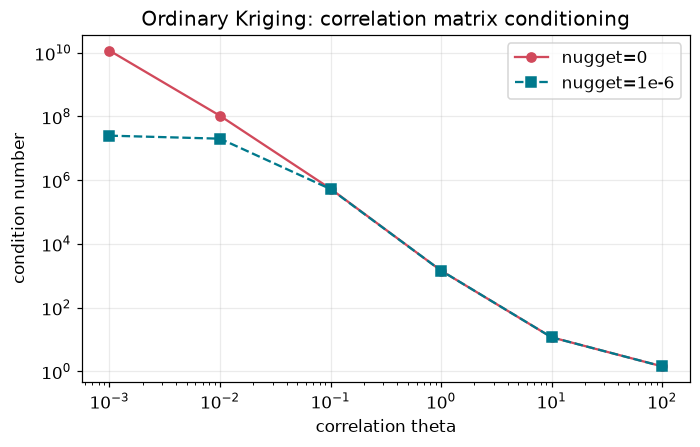

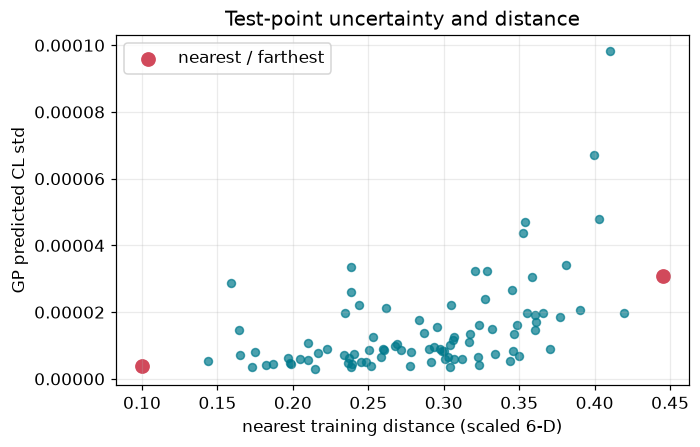

  theta  cond(R), no nugget  cond(R + 1e-6 I)
  0.001        1.167809e+10      2.492245e+07
  0.010        1.049578e+08      2.003320e+07
  0.100        5.374277e+05      5.250097e+05
  1.000        1.445966e+03      1.445774e+03
 10.000        1.167939e+01      1.167932e+01
100.000        1.430026e+00      1.430025e+00
Worst theta=0.001: condition number 1.168e+10 falls to 2.492e+07 with nugget=1e-6.
theta=0.001: subsample interpolation RMSE=1.985e-10
theta=0.01: subsample interpolation RMSE=8.744e-13
theta=0.1: subsample interpolation RMSE=1.524e-14
theta=1: subsample interpolation RMSE=3.400e-16
theta=10: subsample interpolation RMSE=8.938e-17
theta=100: subsample interpolation RMSE=5.065e-17
A large condition number amplifies numerical errors in the correlation solve. A nugget stabilizes it but changes the covariance and exact interpolation.
Fitted GP kernel: 12.7**2 * RBF(length_scale=[5.02, 1.76, 12.1, 5.13, 1.69, 1e+03])
GP fit completed; 3 optimizer warning(s) were captured.
Th

In [7]:
def corr_matrix(X1, X2, theta):
    return np.exp(-theta * cdist(X1, X2, metric='sqeuclidean'))

def kriging_fit(X, y, theta, nugget=0.0):
    R = corr_matrix(X, X, theta) + nugget * np.eye(len(X))
    ones = np.ones(len(X))
    # Solves implement R^{-1}y and R^{-1}1 without forming an inverse.
    Ry, R1 = np.linalg.solve(R, y), np.linalg.solve(R, ones)
    beta = float((ones @ Ry) / (ones @ R1))
    alpha = np.linalg.solve(R, y - beta * ones)
    return {'X': X, 'theta': theta, 'beta': beta, 'alpha': alpha, 'R': R}

def kriging_predict(Xnew, model):
    r = corr_matrix(Xnew, model['X'], model['theta'])
    return model['beta'] + r @ model['alpha']

sub_idx = np.random.default_rng(RNG).choice(len(Xtr_s), size=25, replace=False)
Xsub, ysub = Xtr_s[sub_idx], ytr[sub_idx]
thetas = np.array([1e-3, 1e-2, 1e-1, 1, 10, 100.])
kappas = np.array([np.linalg.cond(corr_matrix(Xsub, Xsub, theta)) for theta in thetas])
kappas_nugget = np.array([np.linalg.cond(corr_matrix(Xsub, Xsub, theta) + 1e-6 * np.eye(25))
                          for theta in thetas])
display(pd.DataFrame({'theta': thetas, 'cond(R), no nugget': kappas,
                      'cond(R + 1e-6 I)': kappas_nugget}))
worst = int(np.argmax(kappas))
print(f'Worst theta={thetas[worst]:g}: condition number {kappas[worst]:.3e} '
      f'falls to {kappas_nugget[worst]:.3e} with nugget=1e-6.')
for theta in thetas:
    try:
        submodel = kriging_fit(Xsub, ysub, theta, nugget=0.0)
        pred = kriging_predict(Xsub, submodel)
        print(f'theta={theta:g}: subsample interpolation RMSE={rmse(ysub, pred):.3e}')
    except np.linalg.LinAlgError:
        print(f'theta={theta:g}: no-nugget solve is singular')
print('A large condition number amplifies numerical errors in the correlation solve. '
      'A nugget stabilizes it but changes the covariance and exact interpolation.')
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.loglog(thetas, kappas, 'o-', color=COLORS['alt'], label='nugget=0')
ax.loglog(thetas, kappas_nugget, 's--', color=COLORS['fit'], label='nugget=1e-6')
ax.set(xlabel='correlation theta', ylabel='condition number',
       title='Ordinary Kriging: correlation matrix conditioning')
ax.legend(); plt.tight_layout(); plt.show()

kernel = ConstantKernel(1.0, (1e-3, 1e3)) * RBFKernel(
    length_scale=np.ones(6), length_scale_bounds=(1e-2, 1e3))
gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True,
                              n_restarts_optimizer=3, random_state=RNG)
# Some random L-BFGS restarts can stop on a flat likelihood direction even
# though another restart finds a valid optimum. Capture only these expected
# sklearn convergence warnings; all other warnings and exceptions remain visible.
with warnings.catch_warnings(record=True) as gp_fit_warnings:
    warnings.simplefilter('always', ConvergenceWarning)
    gp.fit(Xtr_s, ytr)
gp_fit_warnings = [w for w in gp_fit_warnings
                   if issubclass(w.category, ConvergenceWarning)]
yhat_gp, std_gp = gp.predict(Xte_s, return_std=True)
D = cdist(Xte_s, Xtr_s)
min_dist = D.min(axis=1)
i_near, i_far = int(np.argmin(min_dist)), int(np.argmax(min_dist))
print('Fitted GP kernel:', gp.kernel_)
print(f'GP fit completed; {len(gp_fit_warnings)} optimizer warning(s) were captured.')
learned_length_scales = np.asarray(gp.kernel_.k2.length_scale)
if learned_length_scales[-1] >= 0.99 * 1e3:
    print('The log10(Re) length scale reached its upper bound. This means the '
          'likelihood favors almost no variation with Reynolds number over the '
          'sampled range; it does not invalidate the fitted predictor.')
print(f'GP test RMSE={rmse(yte, yhat_gp):.6f}, R2={r2(yte, yhat_gp):.6f}')
print(f'Nearest test point: row={i_near}, distance={min_dist[i_near]:.6f}, '
      f'predicted std={std_gp[i_near]:.6f}')
print(f'Farthest test point: row={i_far}, distance={min_dist[i_far]:.6f}, '
      f'predicted std={std_gp[i_far]:.6f}')
print('GP uncertainty depends on all training locations and learned length scales; '
      'Euclidean nearest-neighbor distance is only a rough guide.')
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(min_dist, std_gp, s=27, alpha=0.7, color=COLORS['fit'])
ax.scatter(min_dist[[i_near, i_far]], std_gp[[i_near, i_far]], s=75,
           color=COLORS['alt'], label='nearest / farthest')
ax.set(xlabel='nearest training distance (scaled 6-D)', ylabel='GP predicted CL std',
       title='Test-point uncertainty and distance')
ax.legend(); plt.tight_layout(); plt.show()

**Answer and interpretation.** The subsample uses the lecture ordinary-Kriging equations with a constant GLS mean, zero nugget for the primary comparison, and direct linear solves. The full-data GP learns one RBF length scale per input by likelihood. Its standard deviations are model-based and depend on the learned kernel. The full GP fit may encounter flat likelihood directions during some optimizer restarts. These convergence warnings are captured locally after confirming that the fit completes. A length scale at its upper bound indicates negligible fitted variation along that input over the sampled domain.

## Bonus (optional, no penalty for skipping) --- Comparing surrogate families

Collect your tuned models (CV-selected; Kriging by maximum likelihood) from questions 3--6 -- quadratic+ridge, RBF, ANN, Kriging -- into one table of test RMSE/$R^2$ for `CL`, each family's complexity knob, and whether it gives native uncertainty quantification (mirroring lecture's "Family / Complexity knob / Native UQ?" comparison). State which family you'd recommend and why, citing a property from the table.

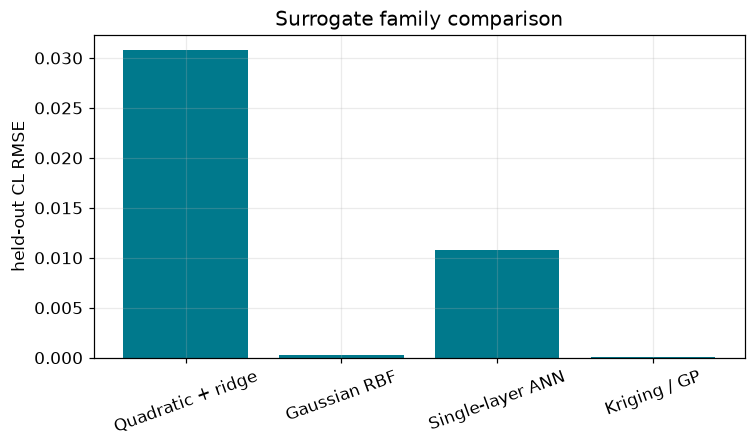

           Family                 Complexity knob  Test RMSE  Test R2            Native UQ
Quadratic + ridge                     lambda=0.01   0.030776 0.995254                   No
     Gaussian RBF                     lambda=0.01   0.000273 1.000000                   No
 Single-layer ANN                       width=128   0.010782 0.999417                   No
     Kriging / GP anisotropic length scales (MLE)   0.000038 1.000000 Yes (predictive std)
Recommendation for prediction of CL: Kriging / GP has the lowest held-out RMSE (0.000038) and R2=1.000000 in this comparison.
If uncertainty estimates are needed, the GP is the only listed family with native predictive standard deviation; its reliability still depends on the GP assumptions.


In [8]:
summary = pd.DataFrame([
    ('Quadratic + ridge', f'lambda={best_ridge_lam:g}', rmse(yte, yhat_ridge),
     r2(yte, yhat_ridge), 'No'),
    ('Gaussian RBF', f'lambda={best_rbf_lam:g}', rmse(yte, yhat_rbf),
     r2(yte, yhat_rbf), 'No'),
    ('Single-layer ANN', f'width={best_width}', rmse(yte, yhat_ann),
     r2(yte, yhat_ann), 'No'),
    ('Kriging / GP', 'anisotropic length scales (MLE)', rmse(yte, yhat_gp),
     r2(yte, yhat_gp), 'Yes (predictive std)'),
], columns=['Family', 'Complexity knob', 'Test RMSE', 'Test R2', 'Native UQ'])
display(summary)
winner = summary.loc[summary['Test RMSE'].idxmin()]
print(f"Recommendation for prediction of CL: {winner['Family']} has the lowest held-out "
      f"RMSE ({winner['Test RMSE']:.6f}) and R2={winner['Test R2']:.6f} in this comparison.")
print('If uncertainty estimates are needed, the GP is the only listed family with native '
      'predictive standard deviation; its reliability still depends on the GP assumptions.')
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.bar(summary['Family'], summary['Test RMSE'], color=COLORS['fit'])
ax.set(ylabel='held-out CL RMSE', title='Surrogate family comparison')
ax.tick_params(axis='x', labelrotation=20)
plt.tight_layout(); plt.show()

**Answer and interpretation.** The recommendation above follows the measured held-out RMSE. Predictive uncertainty, interpretability, fit cost, and numerical stability may alter the choice for a different use case.